## Phenology Dev
Develop methods for calculating various phenology from SNOTEL

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from buildforcing.datasets import PNNLSnotel
from pathlib import Path

import os
from dotenv import load_dotenv
load_dotenv(Path.cwd().parents[0] / ".env")

True

### Load a test site
Some recommended sites
- Cumbres Trestle: Lots of missing years
- Garita Peak: has 11 day gap after melt out one year

In [5]:
site = 'Cumbres Trestle'
snotel_path = os.getenv('SNOTEL_PATH')

In [8]:
snotel = PNNLSnotel(site, snotel_path)
snotel.load_data()

In [9]:
snotel.data

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1980-08-06 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0
1980-08-07 00:00:00-06:00,NaN,NaN,NaN,2.54,0.0
1980-08-08 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0
1980-08-09 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0
1980-08-10 00:00:00-06:00,NaN,NaN,NaN,0.00,0.0
...,...,...,...,...,...
2021-09-26 00:00:00-06:00,16.266667,1.961111,8.827778,NaN,NaN
2021-09-27 00:00:00-06:00,11.116667,1.388889,5.966667,NaN,NaN
2021-09-28 00:00:00-06:00,11.688889,-0.327778,5.394444,NaN,NaN


<Axes: xlabel='Date'>

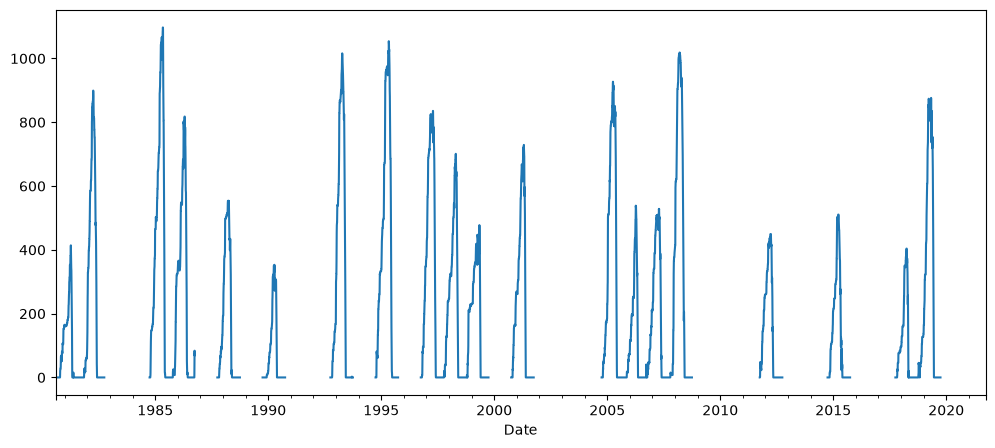

In [10]:
# Initial plot of swe
plt.figure(figsize=(12, 5))
snotel.data['swe_mm'].plot()

### Snow days per water year

Season length is calculated as "snow days": the count of days with `swe_mm` above a threshold within
the snow-relevant window of each water year (Oct 1 - Sep 30, water year labeled by the year containing
Jan-Sep). This avoids needing to detect a single contiguous onset/melt-out span, so it's more robust at
sites with intermittent snowpack.

Missing data is screened per water year, restricted to the plausible snow window (Oct-Jul, excluding
Aug-Sep when SWE is reliably zero). A water year is skipped entirely if either:
- the longest single run of missing days in the window exceeds `MAX_GAP_DAYS`, or
- the total missing days in the window exceed `MAX_GAP_FRACTION` of the window length.

Otherwise, short gaps are linearly interpolated (time-based) before counting snow days.

In [11]:
import numpy as np

# Snow days parameters
SWE_THRESHOLD_MM = 5.0      # SWE above this counts as a "snow day"
SNOW_WINDOW_MONTHS = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7]  # Oct-Jul; Aug-Sep excluded (reliably snow-free)
MAX_GAP_DAYS = 10           # longest single missing run that is safe to interpolate unconditionally
MAX_GAP_DAYS_FLAT = 30      # longest gap allowed when it's bounded by below-threshold SWE on both sides
MAX_GAP_FRACTION = 0.10     # total missing days allowed within the window, as a fraction of window length

In [12]:
def compute_snow_days(
    data: pd.DataFrame,
    swe_col: str = 'swe_mm',
    threshold_mm: float = SWE_THRESHOLD_MM,
    window_months: list[int] = SNOW_WINDOW_MONTHS,
    max_gap_days: int = MAX_GAP_DAYS,
    max_gap_days_flat: int = MAX_GAP_DAYS_FLAT,
    max_gap_fraction: float = MAX_GAP_FRACTION,
) -> pd.DataFrame:
    '''
    Compute snow days per water year (Oct 1 - Sep 30) from a daily SWE series.

    A gap is safe to interpolate if it is no longer than max_gap_days, or -- if longer -- it is
    no longer than max_gap_days_flat AND the SWE values immediately bounding the gap are both
    below threshold_mm (i.e. the gap sits in a snow-free stretch rather than spanning an
    accumulation/melt transition). A water year is skipped (valid=False, snow_days=NaN) if any
    gap fails both checks, or if total missing days in the window exceed max_gap_fraction of the
    window length. Otherwise gaps are linearly interpolated (time-based) before counting days
    with swe_col > threshold_mm.

    Returns a DataFrame indexed by water_year with columns: valid, snow_days, max_gap_days,
    missing_frac, n_window_days.
    '''
    full_swe = data[swe_col]
    df = data[[swe_col]].copy()
    df['water_year'] = np.where(df.index.month >= 10, df.index.year + 1, df.index.year)
    in_window = df.index.month.isin(window_months)

    records = []
    for wy, group in df[in_window].groupby('water_year'):
        n_window = len(group)
        swe = group[swe_col]
        is_missing = swe.isna()
        total_missing = int(is_missing.sum())
        missing_frac = total_missing / n_window

        longest_gap = 0
        gaps_ok = True
        if is_missing.any():
            run_id = (is_missing != is_missing.shift()).cumsum()
            for _, run_index in is_missing[is_missing].groupby(run_id[is_missing]).groups.items():
                gap_len = len(run_index)
                longest_gap = max(longest_gap, gap_len)

                if gap_len <= max_gap_days:
                    continue

                # Longer gap: only acceptable if bounded by below-threshold SWE on both sides
                start_pos = full_swe.index.get_loc(run_index.min())
                end_pos = full_swe.index.get_loc(run_index.max())
                before_val = full_swe.iloc[start_pos - 1] if start_pos > 0 else np.nan
                after_val = full_swe.iloc[end_pos + 1] if end_pos + 1 < len(full_swe) else np.nan
                flat_bounded = (
                    pd.notna(before_val) and pd.notna(after_val)
                    and before_val <= threshold_mm and after_val <= threshold_mm
                )

                if gap_len > max_gap_days_flat or not flat_bounded:
                    gaps_ok = False
                    break

        valid = gaps_ok and (missing_frac <= max_gap_fraction)

        snow_days = np.nan
        if valid:
            interpolated = swe.interpolate(method='time', limit=max_gap_days_flat, limit_area='inside')
            snow_days = int((interpolated > threshold_mm).sum())

        records.append({
            'water_year': wy,
            'valid': valid,
            'snow_days': snow_days,
            'max_gap_days': longest_gap,
            'missing_frac': missing_frac,
            'n_window_days': n_window,
        })

    return pd.DataFrame(records).set_index('water_year')

In [13]:
snow_day_results = compute_snow_days(snotel.data)

n_valid = snow_day_results['valid'].sum()
n_skipped = (~snow_day_results['valid']).sum()
mean_snow_days = snow_day_results.loc[snow_day_results['valid'], 'snow_days'].mean()

print(f"{site}: {n_valid} valid water years, {n_skipped} skipped")
print(f"Mean snow days per season: {mean_snow_days:.1f}")

snow_day_results

Cumbres Trestle: 20 valid water years, 21 skipped
Mean snow days per season: 216.1


,valid,snow_days,max_gap_days,missing_frac,n_window_days
water_year,,,,,
1981,True,199.0,0,0.0,304
1982,True,209.0,0,0.0,304
1983,False,NaN,304,1.0,304
1984,False,NaN,305,1.0,305
1985,True,239.0,0,0.0,304
1986,True,240.0,0,0.0,304
1987,False,NaN,304,1.0,304
1988,True,208.0,0,0.0,305
1989,False,NaN,304,1.0,304


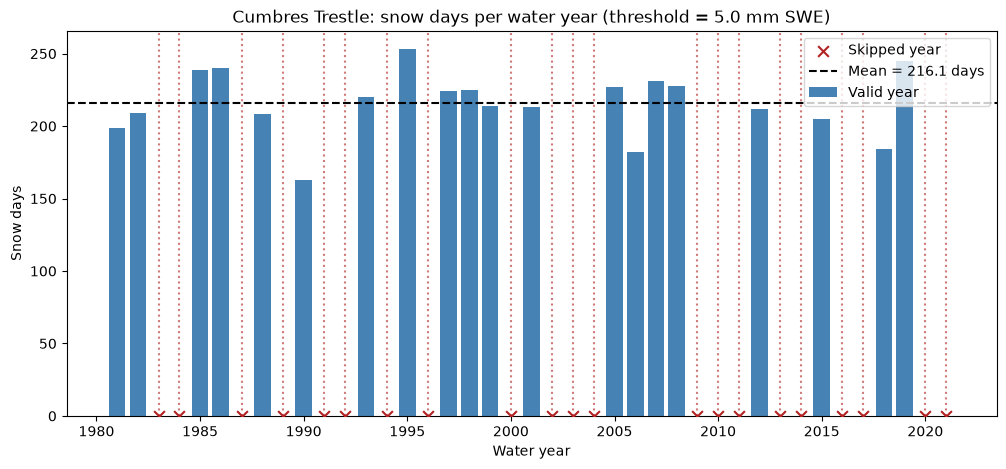

In [14]:
# Plot snow days per water year, marking skipped years and the mean
fig, ax = plt.subplots(figsize=(12, 5))

valid = snow_day_results[snow_day_results['valid']]
skipped = snow_day_results[~snow_day_results['valid']]

ax.bar(valid.index, valid['snow_days'], color='steelblue', label='Valid year')
ax.bar(skipped.index, [0] * len(skipped), color='none')  # keep x-axis ticks for skipped years
for wy in skipped.index:
    ax.axvline(wy, color='firebrick', linestyle=':', alpha=0.6)
ax.scatter(skipped.index, [0] * len(skipped), color='firebrick', marker='x', s=60, label='Skipped year', zorder=3)

ax.axhline(mean_snow_days, color='black', linestyle='--', label=f'Mean = {mean_snow_days:.1f} days')
ax.set_xlabel('Water year')
ax.set_ylabel('Snow days')
ax.set_title(f'{site}: snow days per water year (threshold = {SWE_THRESHOLD_MM} mm SWE)')
ax.legend()
plt.show()

### Compare to model data

In [1]:
from model_datasets.output import LM4ModelOutput 

In [6]:
namelist = 'gbc'
forcing_str = '01011010'
version = '0005'
model = LM4ModelOutput(site=site, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)
model_snow = model.get_data(['snow','snow_depth'],'land_daily')

In [15]:
# Remove timezone from snotel index so it plots with model
snotel.data.index = snotel.data.index.tz_localize(None)

/home/chris/miniconda3/envs/lm4x/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


<Axes: xlabel='Date'>

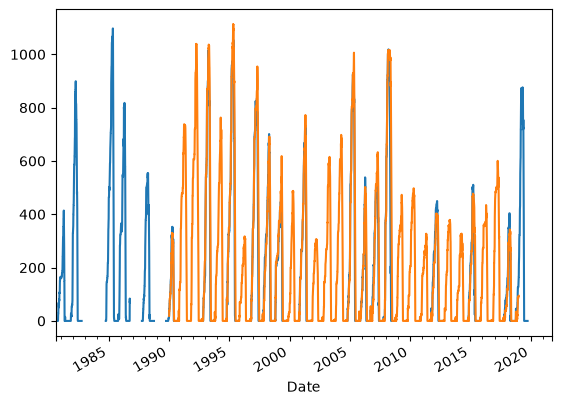

In [16]:
#Comparison plot SNOTEL, model
axs = snotel.data['swe_mm'].plot()
model_snow['snow'].plot(ax=axs)

In [ ]:
plt.close('all')